<a href="https://colab.research.google.com/github/eduardosotouni/Colab/blob/main/SEGUIMIENTO_MICRO_ANT_092026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Specify the directory path
data_path = '/content/drive/MyDrive/DATA/MODELO_NOCONSUMO/SEGUIMIENTO_092026V3'

# Check if the directory exists and list its contents
if os.path.exists(data_path):
    print(f"Contents of '{data_path}':")
    for item in os.listdir(data_path):
        print(item)
else:
    print(f"The directory '{data_path}' does not exist. Please ensure the path is correct and your Drive is mounted properly.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Contents of '/content/drive/MyDrive/DATA/MODELO_NOCONSUMO/SEGUIMIENTO_092026V3':
DATAMIC_2509_V3.csv
DATAMIC_2508_V3.csv
DATAMIC_2507_V3.csv
DATAMIC_2505_V3.csv
DATAMIC_2506_V3.csv


In [37]:
import os
import glob
import pandas as pd

# Si data_path no estuviese definido previamente:
# data_path = '/content/drive/MyDrive/DATA/MODELO_NOCONSUMO/SEGUIMIENTO_092026'

# 1. Búsqueda automática de los archivos que coincidan con el patrón
# (o puedes mantener la lista manual si solo quieres meses específicos)
archivos = sorted(glob.glob(os.path.join(data_path, 'DATA*.csv')))

dfs = []

for file_path in archivos:
    file_name = os.path.basename(file_path)
    print(f"Cargando {file_name}...")
    try:
        # engine='c' es el más rápido por defecto
        df = pd.read_csv(
            file_path,
            sep=';',
            quotechar='"',
            encoding='utf-8',
            low_memory=False
        )
        dfs.append(df)
        print(f"  ✓ {file_name}: {df.shape[0]:,} filas, {df.shape[1]} columnas.")
    except Exception as e:
        print(f"  ✕ Error al cargar {file_name}: {e}")

# 2. Concatenación en un solo DataFrame
if dfs:
    combined_df = pd.concat(dfs, ignore_index=True)
    # Liberar memoria de la lista temporal
    del dfs

    print(f"\nDataFrame consolidado exitosamente:")
    print(f"Total filas: {combined_df.shape[0]:,} | Columnas: {combined_df.shape[1]}")
    display(combined_df.head())
else:
    print("No se logró cargar ningún archivo.")

Cargando DATAMIC_2505_V3.csv...
  ✓ DATAMIC_2505_V3.csv: 195,266 filas, 6 columnas.
Cargando DATAMIC_2506_V3.csv...
  ✓ DATAMIC_2506_V3.csv: 185,541 filas, 6 columnas.
Cargando DATAMIC_2507_V3.csv...
  ✓ DATAMIC_2507_V3.csv: 191,780 filas, 6 columnas.
Cargando DATAMIC_2508_V3.csv...
  ✓ DATAMIC_2508_V3.csv: 193,865 filas, 6 columnas.
Cargando DATAMIC_2509_V3.csv...
  ✓ DATAMIC_2509_V3.csv: 197,455 filas, 6 columnas.

DataFrame consolidado exitosamente:
Total filas: 963,907 | Columnas: 6


,FEC_REPORTE,COD_SBS,NRO_DOC_IDEN,PD,FLAG_RD,MESES_SKCG_POS
0,31/05/2025,198897,27680389,0.039290,0,12
1,31/05/2025,430021,1210483,0.094313,0,12
2,31/05/2025,482919,9099511,0.094729,0,12
3,31/05/2025,1125435,22285140,0.109570,0,12
4,31/05/2025,1394371,18117872,0.055475,0,12


Resumen por rango de PD (incluye SPD)


RANGO_PD,Total_Clientes,Promedio_PD_Calibrada,Promedio_RD60,Pct_Clientes
D1 | 1.0% – 3.9%,"96,391",2.97%,2.30%,10.0%
D2 | 3.9% – 5.3%,"96,391",4.61%,3.08%,10.0%
D3 | 5.3% – 6.6%,"96,391",5.90%,4.23%,10.0%
D4 | 6.6% – 8.0%,"96,524",7.30%,6.05%,10.0%
D5 | 8.0% – 9.6%,"96,387",8.80%,7.65%,10.0%
D6 | 9.6% – 11.5%,"96,260",10.53%,9.24%,10.0%
D7 | 11.5% – 13.5%,"96,391",12.46%,11.95%,10.0%
D8 | 13.5% – 16.6%,"96,393",14.92%,13.88%,10.0%
D9 | 16.6% – 22.7%,"96,530",19.19%,15.79%,10.0%
D10 | 22.7% – 79.3%,"96,249",29.90%,24.33%,10.0%


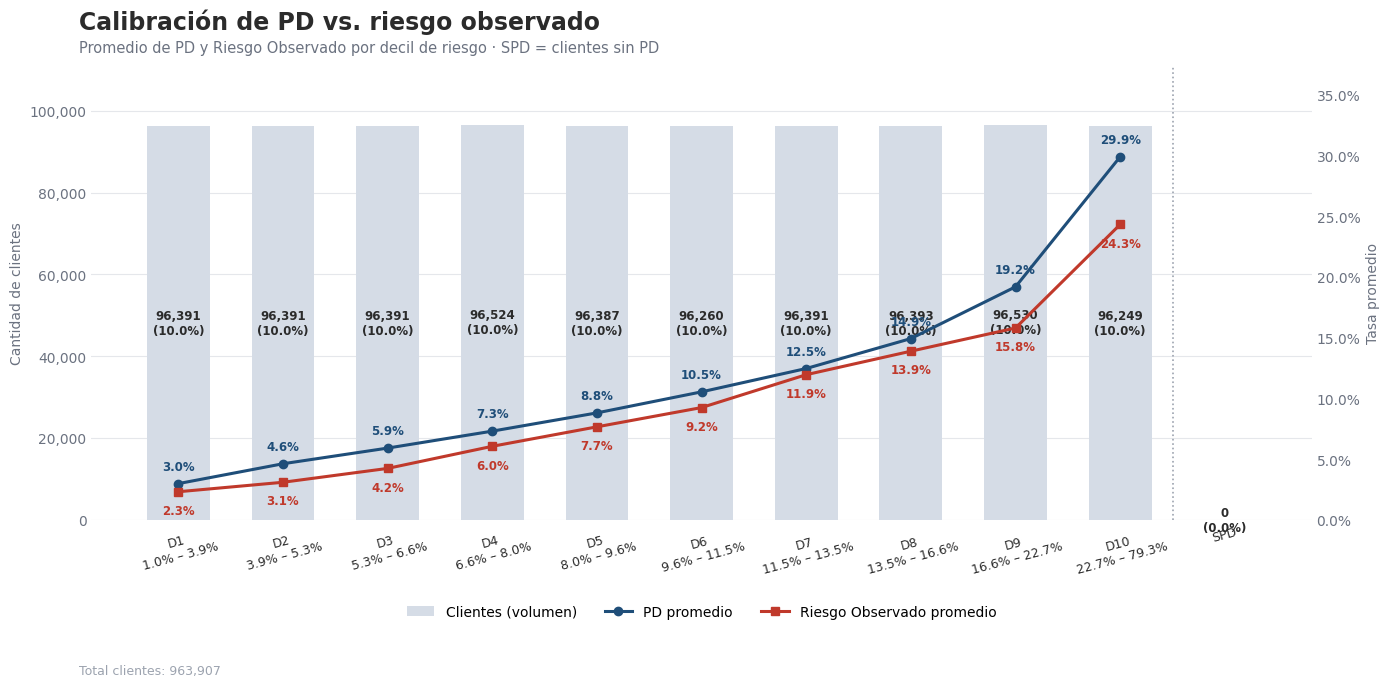

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ------------------------------------------------------------------
# 1. Segmentación: deciles de PD (ordenados) + grupo SPD
# ------------------------------------------------------------------
N_BINS = 10
df = combined_df.copy()  # no modifica el dataframe original
mask = df['PD'].notnull()

codes, bins = pd.qcut(
    df.loc[mask, 'PD'], q=N_BINS, labels=False,
    retbins=True, duplicates='drop'
)
n = len(bins) - 1
labels = [f"D{i+1}\n{bins[i]:.1%} – {bins[i+1]:.1%}" for i in range(n)]
orden = labels + ['SPD']

df['RANGO_PD'] = 'SPD'
df.loc[mask, 'RANGO_PD'] = codes.map(dict(enumerate(labels)))
df['RANGO_PD'] = pd.Categorical(df['RANGO_PD'], categories=orden, ordered=True)

# ------------------------------------------------------------------
# 2. Agregación
# ------------------------------------------------------------------
col_rd60 = [c for c in df.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd60:
    target_col = col_rd60[0]

    analisis_df = (
        df.groupby('RANGO_PD', observed=False)
          .agg(Total_Clientes=('PD', 'size'),
               Promedio_PD_Calibrada=('PD', 'mean'),
               Promedio_RD60=(target_col, 'mean'))
          .reset_index()
    )
    analisis_df['Pct_Clientes'] = analisis_df['Total_Clientes'] / analisis_df['Total_Clientes'].sum()
    analisis_df['RANGO_PD'] = analisis_df['RANGO_PD'].astype(str)

    # Tabla resumen con formato
    tabla = analisis_df.copy()
    tabla['RANGO_PD'] = tabla['RANGO_PD'].str.replace('\n', ' | ')
    print("Resumen por rango de PD (incluye SPD)")
    display(
        tabla.style
             .format({'Total_Clientes': '{:,.0f}',
                      'Pct_Clientes': '{:.1%}',
                      'Promedio_PD_Calibrada': '{:.2%}',
                      'Promedio_RD60': '{:.2%}'})
             .hide(axis='index')
             .background_gradient(subset=['Promedio_RD60'], cmap='Reds')
    )

    # --------------------------------------------------------------
    # 3. Gráfico ejecutivo
    # --------------------------------------------------------------
    C_BAR, C_SPD = '#D5DCE6', '#B0B7C3'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_df))
    colores = [C_BAR] * n + [C_SPD]

    # Barras: volumen de clientes
    bars = ax1.bar(x, analisis_df['Total_Clientes'], color=colores, width=0.6,
                   zorder=2, label='Clientes (volumen)')
    bars[-1].set_hatch('///')
    bars[-1].set_edgecolor('white')

    for rect, tot, pct in zip(bars, analisis_df['Total_Clientes'], analisis_df['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=8.5, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_df['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_df['RANGO_PD'], fontsize=9, color=C_TXT, rotation=15)
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Separador visual entre deciles y SPD
    ax1.axvline(n - 0.5, color='#9CA3AF', linestyle=':', linewidth=1.2)

    # Líneas: PD y RD (solo sobre deciles ordenados; SPD va como punto aislado)
    ax2 = ax1.twinx()
    xs = x[:n]

    ax2.plot(xs, analisis_df['Promedio_PD_Calibrada'][:n], color=C_PD, marker='o',
             markersize=6, linewidth=2.2, label='PD promedio', zorder=4)
    ax2.plot(xs, analisis_df['Promedio_RD60'][:n], color=C_RD, marker='s',
             markersize=6, linewidth=2.2, label='Riesgo Observado promedio', zorder=4)
    ax2.scatter([x[-1]], [analisis_df['Promedio_RD60'].iloc[-1]], color=C_RD,
                marker='s', s=60, zorder=4)

    # Etiquetas de datos sobre las líneas
    for xi, v in zip(xs, analisis_df['Promedio_PD_Calibrada'][:n]):
        ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=8.5, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_df['Promedio_RD60']):
        if pd.notnull(v):
            ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, -16),
                         ha='center', fontsize=8.5, color=C_RD, fontweight='bold')

    ymax = np.nanmax([analisis_df['Promedio_PD_Calibrada'].max(),
                      analisis_df['Promedio_RD60'].max()])
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Limpieza de bordes
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Título y subtítulo
    fig.text(0.06, 0.96, 'Calibración de PD vs. riesgo observado',
             fontsize=17, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Promedio de PD y Riesgo Observado por decil de riesgo · SPD = clientes sin PD',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada, debajo del gráfico
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.16),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes: {analisis_df['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.04, 1, 0.90])
    plt.show()

else:
    print("No se encontró una columna de riesgo observado. Columnas disponibles:")
    print(list(df.columns))

Resumen por rango de PD (Periodo: 202509, incluye SPD)


RANGO_PD,Total_Clientes,Promedio_PD_Calibrada,Promedio_RD60,Pct_Clientes
D1 | 1.1% – 3.9%,"19,746",2.98%,2.31%,10.0%
D2 | 3.9% – 5.2%,"19,745",4.60%,3.10%,10.0%
D3 | 5.2% – 6.6%,"19,746",5.89%,4.27%,10.0%
D4 | 6.6% – 8.0%,"19,837",7.28%,6.59%,10.0%
D5 | 8.0% – 9.6%,"19,654",8.78%,8.45%,10.0%
D6 | 9.6% – 11.4%,"19,746",10.50%,9.81%,10.0%
D7 | 11.4% – 13.5%,"19,778",12.43%,13.20%,10.0%
D8 | 13.5% – 16.5%,"19,712",14.87%,15.10%,10.0%
D9 | 16.5% – 22.6%,"19,745",19.15%,17.28%,10.0%
D10 | 22.6% – 76.4%,"19,746",29.83%,26.16%,10.0%


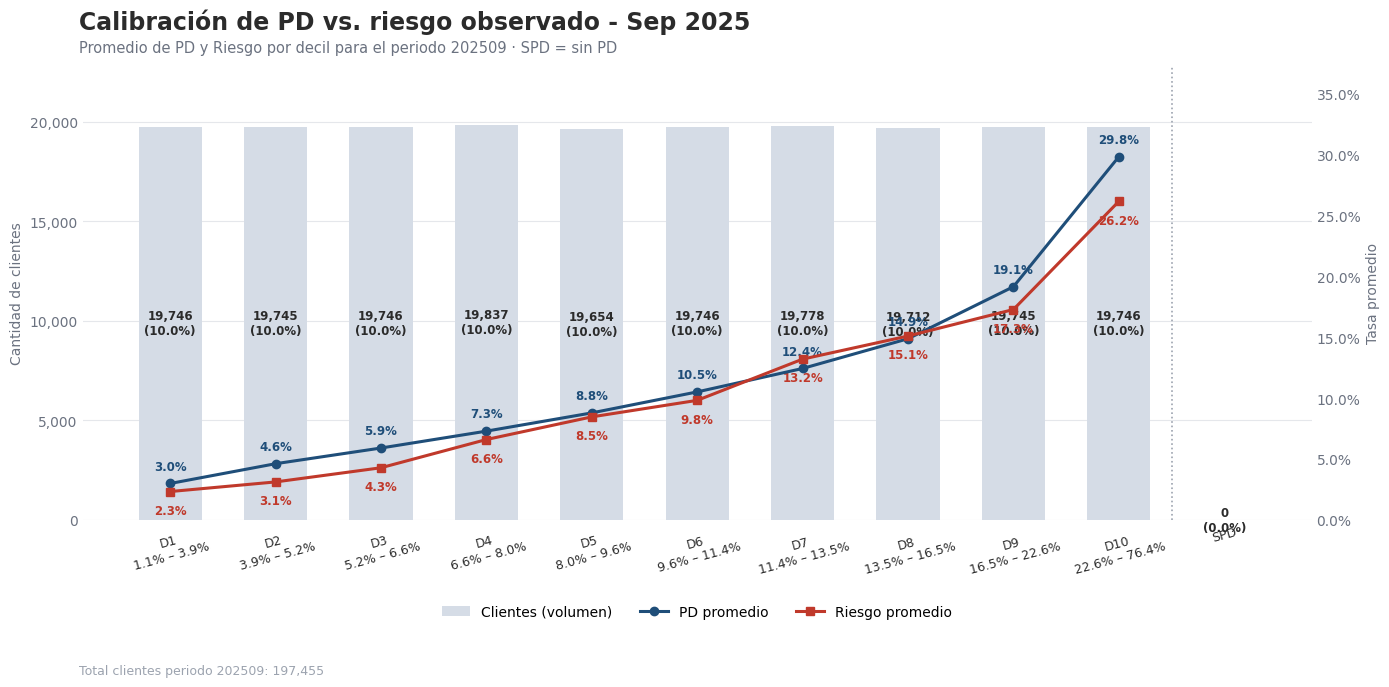

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ------------------------------------------------------------------
# 0. Filtrar la información para el periodo 202509 (Septiembre 2025)
# ------------------------------------------------------------------
df_full = combined_df.copy()
# Convertimos FEC_REPORTE a formato de fecha para realizar el filtro de manera segura
df_full['FEC_REPORTE_DT'] = pd.to_datetime(df_full['FEC_REPORTE'], format='%d/%m/%Y', errors='coerce')

# Filtro estricto para Año 2025, Mes 9
filtro_periodo = (df_full['FEC_REPORTE_DT'].dt.year == 2025) & (df_full['FEC_REPORTE_DT'].dt.month == 9)
df = df_full[filtro_periodo].copy()

# ------------------------------------------------------------------
# 1. Segmentación: deciles de PD (ordenados) + grupo SPD
# ------------------------------------------------------------------
N_BINS = 10
mask = df['PD'].notnull()

codes, bins = pd.qcut(
    df.loc[mask, 'PD'], q=N_BINS, labels=False,
    retbins=True, duplicates='drop'
)
n = len(bins) - 1
labels = [f"D{i+1}\n{bins[i]:.1%} – {bins[i+1]:.1%}" for i in range(n)]
orden = labels + ['SPD']

df['RANGO_PD'] = 'SPD'
df.loc[mask, 'RANGO_PD'] = codes.map(dict(enumerate(labels)))
df['RANGO_PD'] = pd.Categorical(df['RANGO_PD'], categories=orden, ordered=True)

# ------------------------------------------------------------------
# 2. Agregación
# ------------------------------------------------------------------
col_rd60 = [c for c in df.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd60:
    target_col = col_rd60[0]

    analisis_df = (
        df.groupby('RANGO_PD', observed=False)
          .agg(Total_Clientes=('PD', 'size'),
               Promedio_PD_Calibrada=('PD', 'mean'),
               Promedio_RD60=(target_col, 'mean'))
          .reset_index()
    )
    analisis_df['Pct_Clientes'] = analisis_df['Total_Clientes'] / analisis_df['Total_Clientes'].sum()
    analisis_df['RANGO_PD'] = analisis_df['RANGO_PD'].astype(str)

    # Tabla resumen con formato
    tabla = analisis_df.copy()
    tabla['RANGO_PD'] = tabla['RANGO_PD'].str.replace('\n', ' | ')
    print("Resumen por rango de PD (Periodo: 202509, incluye SPD)")
    display(
        tabla.style
             .format({'Total_Clientes': '{:,.0f}',
                      'Pct_Clientes': '{:.1%}',
                      'Promedio_PD_Calibrada': '{:.2%}',
                      'Promedio_RD60': '{:.2%}'})
             .hide(axis='index')
             .background_gradient(subset=['Promedio_RD60'], cmap='Reds')
    )

    # --------------------------------------------------------------
    # 3. Gráfico ejecutivo
    # --------------------------------------------------------------
    C_BAR, C_SPD = '#D5DCE6', '#B0B7C3'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_df))
    colores = [C_BAR] * n + [C_SPD]

    # Barras: volumen de clientes
    bars = ax1.bar(x, analisis_df['Total_Clientes'], color=colores, width=0.6,
                   zorder=2, label='Clientes (volumen)')
    bars[-1].set_hatch('///')
    bars[-1].set_edgecolor('white')

    for rect, tot, pct in zip(bars, analisis_df['Total_Clientes'], analisis_df['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=8.5, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_df['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_df['RANGO_PD'], fontsize=9, color=C_TXT, rotation=15)
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Separador visual entre deciles y SPD
    ax1.axvline(n - 0.5, color='#9CA3AF', linestyle=':', linewidth=1.2)

    # Líneas: PD y RD60 (solo sobre deciles ordenados; SPD va como punto aislado)
    ax2 = ax1.twinx()
    xs = x[:n]

    ax2.plot(xs, analisis_df['Promedio_PD_Calibrada'][:n], color=C_PD, marker='o',
             markersize=6, linewidth=2.2, label='PD promedio', zorder=4)
    ax2.plot(xs, analisis_df['Promedio_RD60'][:n], color=C_RD, marker='s',
             markersize=6, linewidth=2.2, label='Riesgo promedio', zorder=4)
    ax2.scatter([x[-1]], [analisis_df['Promedio_RD60'].iloc[-1]], color=C_RD,
                marker='s', s=60, zorder=4)

    # Etiquetas de datos sobre las líneas
    for xi, v in zip(xs, analisis_df['Promedio_PD_Calibrada'][:n]):
        ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=8.5, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_df['Promedio_RD60']):
        if pd.notnull(v):
            ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, -16),
                         ha='center', fontsize=8.5, color=C_RD, fontweight='bold')

    ymax = np.nanmax([analisis_df['Promedio_PD_Calibrada'].max(),
                      analisis_df['Promedio_RD60'].max()])
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Limpieza de bordes
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Título y subtítulo
    fig.text(0.06, 0.96, 'Calibración de PD vs. riesgo observado - Sep 2025',
             fontsize=17, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Promedio de PD y Riesgo por decil para el periodo 202509 · SPD = sin PD',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada, debajo del gráfico
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.16),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes periodo 202509: {analisis_df['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.04, 1, 0.90])
    plt.show()

else:
    print("No se encontró una columna de riesgo observado. Columnas disponibles:")
    print(list(df.columns))

Resumen por rango de PD (Periodo: Ago - Sep 2025, incluye SPD)


RANGO_PD,Total_Clientes,Promedio_PD_Calibrada,Promedio_RD60,Pct_Clientes
D1 | 1.1% – 3.9%,"39,135",2.97%,2.24%,10.0%
D2 | 3.9% – 5.2%,"39,130",4.60%,3.09%,10.0%
D3 | 5.2% – 6.6%,"39,131",5.88%,4.33%,10.0%
D4 | 6.6% – 8.0%,"39,181",7.26%,6.34%,10.0%
D5 | 8.0% – 9.6%,"39,083",8.76%,8.20%,10.0%
D6 | 9.6% – 11.4%,"39,133",10.48%,9.74%,10.0%
D7 | 11.4% – 13.5%,"39,328",12.41%,12.74%,10.1%
D8 | 13.5% – 16.5%,"38,935",14.88%,14.82%,9.9%
D9 | 16.5% – 22.6%,"39,138",19.14%,16.94%,10.0%
D10 | 22.6% – 79.3%,"39,126",29.83%,25.58%,10.0%


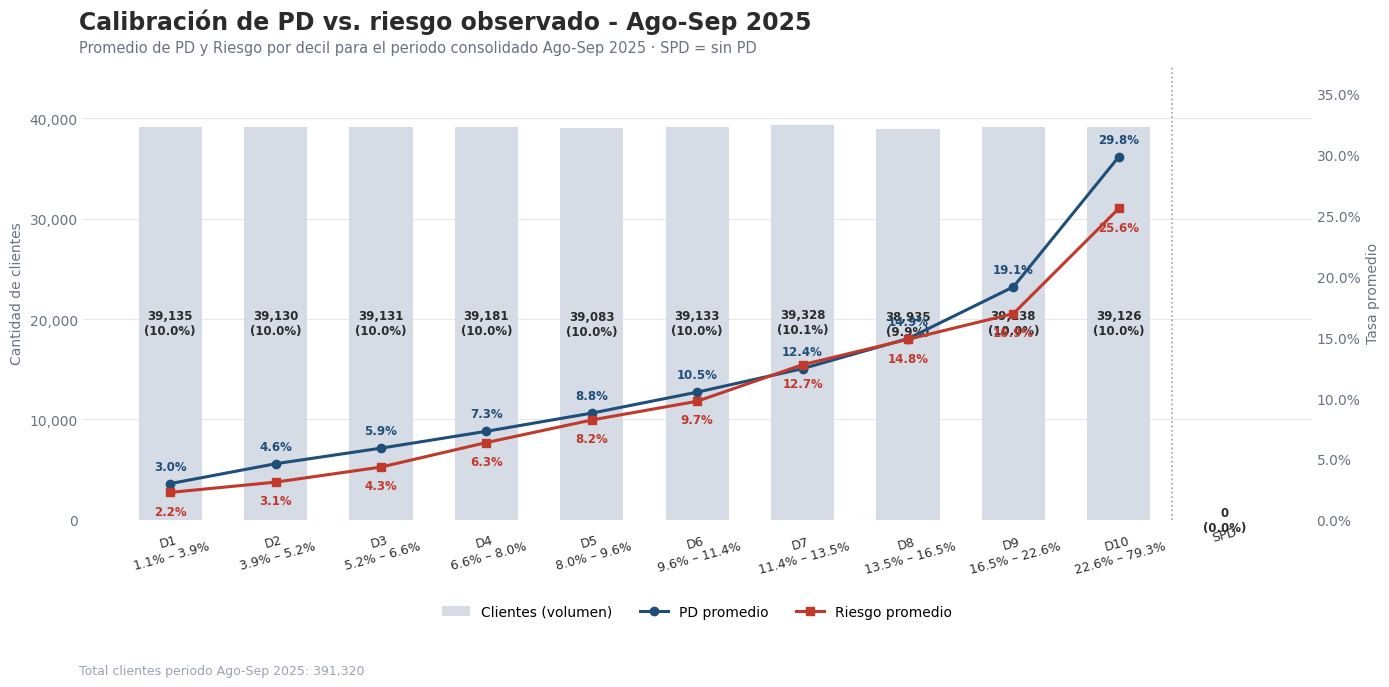

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ------------------------------------------------------------------
# 0. Filtrar la información para el periodo Ago - Sep 2025 (202508 y 202509)
# ------------------------------------------------------------------
df_full = combined_df.copy()
# Convertimos FEC_REPORTE a formato de fecha para realizar el filtro de manera segura
df_full['FEC_REPORTE_DT'] = pd.to_datetime(df_full['FEC_REPORTE'], format='%d/%m/%Y', errors='coerce')

# Filtro estricto para Año 2025, Meses 8 y 9
filtro_periodo = (df_full['FEC_REPORTE_DT'].dt.year == 2025) & (df_full['FEC_REPORTE_DT'].dt.month.isin([8, 9]))
df = df_full[filtro_periodo].copy()

# ------------------------------------------------------------------
# 1. Segmentación: deciles de PD (ordenados) + grupo SPD
# ------------------------------------------------------------------
N_BINS = 10
mask = df['PD'].notnull()

codes, bins = pd.qcut(
    df.loc[mask, 'PD'], q=N_BINS, labels=False,
    retbins=True, duplicates='drop'
)
n = len(bins) - 1
labels = [f"D{i+1}\n{bins[i]:.1%} – {bins[i+1]:.1%}" for i in range(n)]
orden = labels + ['SPD']

df['RANGO_PD'] = 'SPD'
df.loc[mask, 'RANGO_PD'] = codes.map(dict(enumerate(labels)))
df['RANGO_PD'] = pd.Categorical(df['RANGO_PD'], categories=orden, ordered=True)

# ------------------------------------------------------------------
# 2. Agregación
# ------------------------------------------------------------------
col_rd60 = [c for c in df.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd60:
    target_col = col_rd60[0]

    analisis_df = (
        df.groupby('RANGO_PD', observed=False)
          .agg(Total_Clientes=('PD', 'size'),
               Promedio_PD_Calibrada=('PD', 'mean'),
               Promedio_RD60=(target_col, 'mean'))
          .reset_index()
    )
    analisis_df['Pct_Clientes'] = analisis_df['Total_Clientes'] / analisis_df['Total_Clientes'].sum()
    analisis_df['RANGO_PD'] = analisis_df['RANGO_PD'].astype(str)

    # Tabla resumen con formato
    tabla = analisis_df.copy()
    tabla['RANGO_PD'] = tabla['RANGO_PD'].str.replace('\n', ' | ')
    print("Resumen por rango de PD (Periodo: Ago - Sep 2025, incluye SPD)")
    display(
        tabla.style
             .format({'Total_Clientes': '{:,.0f}',
                      'Pct_Clientes': '{:.1%}',
                      'Promedio_PD_Calibrada': '{:.2%}',
                      'Promedio_RD60': '{:.2%}'})
             .hide(axis='index')
             .background_gradient(subset=['Promedio_RD60'], cmap='Reds')
    )

    # --------------------------------------------------------------
    # 3. Gráfico ejecutivo
    # --------------------------------------------------------------
    C_BAR, C_SPD = '#D5DCE6', '#B0B7C3'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_df))
    colores = [C_BAR] * n + [C_SPD]

    # Barras: volumen de clientes
    bars = ax1.bar(x, analisis_df['Total_Clientes'], color=colores, width=0.6,
                   zorder=2, label='Clientes (volumen)')
    bars[-1].set_hatch('///')
    bars[-1].set_edgecolor('white')

    for rect, tot, pct in zip(bars, analisis_df['Total_Clientes'], analisis_df['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=8.5, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_df['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_df['RANGO_PD'], fontsize=9, color=C_TXT, rotation=15)
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Separador visual entre deciles y SPD
    ax1.axvline(n - 0.5, color='#9CA3AF', linestyle=':', linewidth=1.2)

    # Líneas: PD y RD60 (solo sobre deciles ordenados; SPD va como punto aislado)
    ax2 = ax1.twinx()
    xs = x[:n]

    ax2.plot(xs, analisis_df['Promedio_PD_Calibrada'][:n], color=C_PD, marker='o',
             markersize=6, linewidth=2.2, label='PD promedio', zorder=4)
    ax2.plot(xs, analisis_df['Promedio_RD60'][:n], color=C_RD, marker='s',
             markersize=6, linewidth=2.2, label='Riesgo promedio', zorder=4)
    ax2.scatter([x[-1]], [analisis_df['Promedio_RD60'].iloc[-1]], color=C_RD,
                marker='s', s=60, zorder=4)

    # Etiquetas de datos sobre las líneas
    for xi, v in zip(xs, analisis_df['Promedio_PD_Calibrada'][:n]):
        ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=8.5, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_df['Promedio_RD60']):
        if pd.notnull(v):
            ax2.annotate(f"{v:.1%}", (xi, v), textcoords='offset points', xytext=(0, -16),
                         ha='center', fontsize=8.5, color=C_RD, fontweight='bold')

    ymax = np.nanmax([analisis_df['Promedio_PD_Calibrada'].max(),
                      analisis_df['Promedio_RD60'].max()])
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Limpieza de bordes
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Título y subtítulo
    fig.text(0.06, 0.96, 'Calibración de PD vs. riesgo observado - Ago-Sep 2025',
             fontsize=17, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Promedio de PD y Riesgo por decil para el periodo consolidado Ago-Sep 2025 · SPD = sin PD',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada, debajo del gráfico
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.16),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes periodo Ago-Sep 2025: {analisis_df['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.04, 1, 0.90])
    plt.show()

else:
    print("No se encontró una columna de riesgo observado. Columnas disponibles:")
    print(list(df.columns))

Resumen por quintil de PD (incluye SPD)


RANGO_PD,Total_Clientes,Promedio_PD_Calibrada,Promedio_RD60,Pct_Clientes
Q1 | 1.0% – 5.3%,"192,782",3.79%,2.69%,20.0%
Q2 | 5.3% – 8.0%,"192,915",6.60%,5.14%,20.0%
Q3 | 8.0% – 11.5%,"192,647",9.66%,8.44%,20.0%
Q4 | 11.5% – 16.6%,"192,784",13.69%,12.91%,20.0%
Q5 | 16.6% – 79.3%,"192,779",24.54%,20.05%,20.0%
SPD,0,nan%,nan%,0.0%


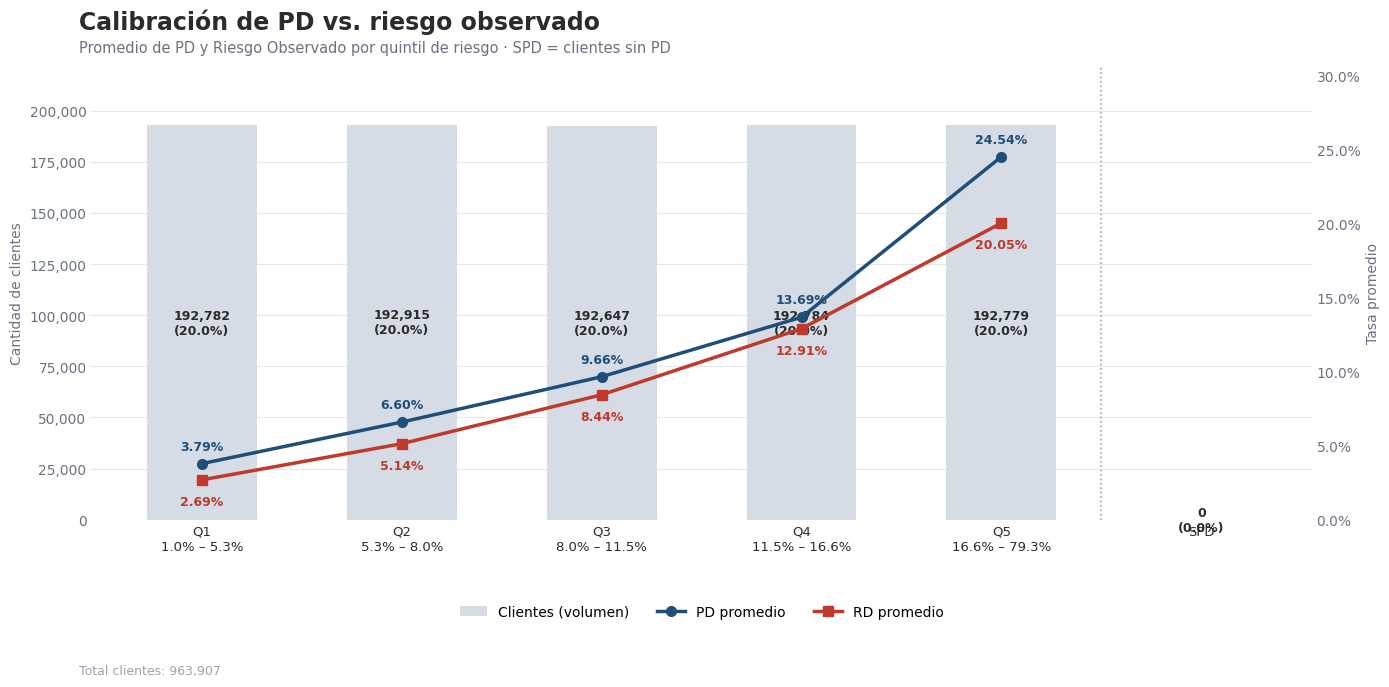

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ------------------------------------------------------------------
# 1. Segmentación: quintiles de PD + grupo SPD
# ------------------------------------------------------------------
N_BINS = 5
df = combined_df.copy()  # no modifica el dataframe original
mask = df['PD'].notnull()

codes, bins = pd.qcut(
    df.loc[mask, 'PD'], q=N_BINS, labels=False,
    retbins=True, duplicates='drop'
)
n = len(bins) - 1
labels = [f"Q{i+1}\n{bins[i]:.1%} – {bins[i+1]:.1%}" for i in range(n)]
orden = labels + ['SPD']

df['RANGO_PD'] = 'SPD'
df.loc[mask, 'RANGO_PD'] = codes.map(dict(enumerate(labels)))
df['RANGO_PD'] = pd.Categorical(df['RANGO_PD'], categories=orden, ordered=True)

# ------------------------------------------------------------------
# 2. Agregación
# ------------------------------------------------------------------
col_rd60 = [c for c in df.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd60:
    target_col = col_rd60[0]

    analisis_df = (
        df.groupby('RANGO_PD', observed=False)
          .agg(Total_Clientes=('PD', 'size'),
               Promedio_PD_Calibrada=('PD', 'mean'),
               Promedio_RD60=(target_col, 'mean'))
          .reset_index()
    )
    analisis_df['Pct_Clientes'] = analisis_df['Total_Clientes'] / analisis_df['Total_Clientes'].sum()
    analisis_df['RANGO_PD'] = analisis_df['RANGO_PD'].astype(str)

    # Tabla resumen con formato
    tabla = analisis_df.copy()
    tabla['RANGO_PD'] = tabla['RANGO_PD'].str.replace('\n', ' | ')
    print("Resumen por quintil de PD (incluye SPD)")
    display(
        tabla.style
             .format({'Total_Clientes': '{:,.0f}',
                      'Pct_Clientes': '{:.1%}',
                      'Promedio_PD_Calibrada': '{:.2%}',
                      'Promedio_RD60': '{:.2%}'})
             .hide(axis='index')
             .background_gradient(subset=['Promedio_RD60'], cmap='Reds')
    )

    # --------------------------------------------------------------
    # 3. Gráfico ejecutivo
    # --------------------------------------------------------------
    C_BAR, C_SPD = '#D5DCE6', '#B0B7C3'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(14, 7))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_df))
    colores = [C_BAR] * n + [C_SPD]

    # Barras: volumen de clientes
    bars = ax1.bar(x, analisis_df['Total_Clientes'], color=colores, width=0.55,
                   zorder=2, label='Clientes (volumen)')
    bars[-1].set_hatch('///')
    bars[-1].set_edgecolor('white')

    for rect, tot, pct in zip(bars, analisis_df['Total_Clientes'], analisis_df['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=9, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_df['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_df['RANGO_PD'], fontsize=9.5, color=C_TXT, rotation=0)
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Separador visual entre quintiles y SPD
    ax1.axvline(n - 0.5, color='#9CA3AF', linestyle=':', linewidth=1.2)

    # Líneas: PD y RD (solo sobre quintiles ordenados; SPD va como punto aislado)
    ax2 = ax1.twinx()
    xs = x[:n]

    ax2.plot(xs, analisis_df['Promedio_PD_Calibrada'][:n], color=C_PD, marker='o',
             markersize=7, linewidth=2.5, label='PD promedio', zorder=4)
    ax2.plot(xs, analisis_df['Promedio_RD60'][:n], color=C_RD, marker='s',
             markersize=7, linewidth=2.5, label='RD promedio', zorder=4)
    ax2.scatter([x[-1]], [analisis_df['Promedio_RD60'].iloc[-1]], color=C_RD,
                marker='s', s=60, zorder=4)

    # Etiquetas de datos sobre las líneas
    for xi, v in zip(xs, analisis_df['Promedio_PD_Calibrada'][:n]):
        ax2.annotate(f"{v:.2%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=9, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_df['Promedio_RD60']):
        if pd.notnull(v):
            ax2.annotate(f"{v:.2%}", (xi, v), textcoords='offset points', xytext=(0, -18),
                         ha='center', fontsize=9, color=C_RD, fontweight='bold')

    ymax = np.nanmax([analisis_df['Promedio_PD_Calibrada'].max(),
                      analisis_df['Promedio_RD60'].max()])
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Limpieza de bordes
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Título y subtítulo
    fig.text(0.06, 0.96, 'Calibración de PD vs. riesgo observado',
             fontsize=17, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Promedio de PD y Riesgo Observado por quintil de riesgo · SPD = clientes sin PD',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada, debajo del gráfico
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.16),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes: {analisis_df['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.04, 1, 0.90])
    plt.show()

else:
    print("No se encontró una columna de riesgo observado. Columnas disponibles:")
    print(list(df.columns))

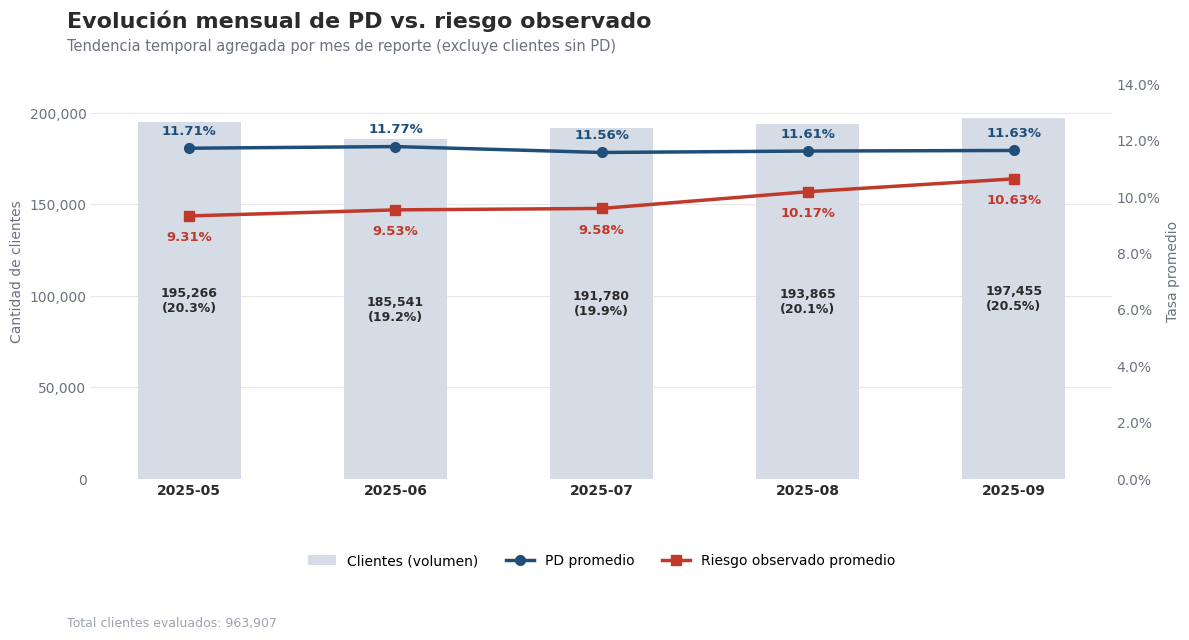

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# 1. Preparar datos temporales
df_temp = combined_df.copy()

# Convertir FEC_REPORTE a formato datetime para asegurar orden cronológico correcto
df_temp['FEC_REPORTE_DT'] = pd.to_datetime(df_temp['FEC_REPORTE'], format='%d/%m/%Y', errors='coerce')

# Agrupar por mes (YYYY-MM) o por el texto del reporte ordenado cronológicamente
df_temp['MES'] = df_temp['FEC_REPORTE_DT'].dt.to_period('M')

# 2. Agregación de métricas por Mes
# Excluimos nulos en PD para calcular promedios reales del modelo
mask_val = df_temp['PD'].notnull()
col_rd = [c for c in df_temp.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd:
    target_col = col_rd[0]

    analisis_mes = (
        df_temp[mask_val].groupby('MES')
        .agg(Total_Clientes=('PD', 'size'),
             Promedio_PD_Calibrada=('PD', 'mean'),
             Promedio_RD60=(target_col, 'mean'))
        .reset_index()
    )

    analisis_mes['Pct_Clientes'] = analisis_mes['Total_Clientes'] / analisis_mes['Total_Clientes'].sum()
    analisis_mes['MES_STR'] = analisis_mes['MES'].astype(str)

    # 3. Diseño del gráfico ejecutivo por mes
    C_BAR = '#D5DCE6'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(12, 6.5))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_mes))

    # Barras: volumen de clientes por mes
    bars = ax1.bar(x, analisis_mes['Total_Clientes'], color=C_BAR, width=0.5, zorder=2, label='Clientes (volumen)')

    for rect, tot, pct in zip(bars, analisis_mes['Total_Clientes'], analisis_mes['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=9, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_mes['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_mes['MES_STR'], fontsize=10, color=C_TXT, fontweight='bold')
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Eje secundario para PD y riesgo
    ax2 = ax1.twinx()

    ax2.plot(x, analisis_mes['Promedio_PD_Calibrada'], color=C_PD, marker='o',
             markersize=7, linewidth=2.5, label='PD promedio', zorder=4)
    ax2.plot(x, analisis_mes['Promedio_RD60'], color=C_RD, marker='s',
             markersize=7, linewidth=2.5, label='Riesgo observado promedio', zorder=4)

    # Etiquetas de datos en las líneas
    for xi, v in zip(x, analisis_mes['Promedio_PD_Calibrada']):
        ax2.annotate(f"{v:.2%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=9.5, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_mes['Promedio_RD60']):
        ax2.annotate(f"{v:.2%}", (xi, v), textcoords='offset points', xytext=(0, -18),
                     ha='center', fontsize=9.5, color=C_RD, fontweight='bold')

    ymax = max(analisis_mes['Promedio_PD_Calibrada'].max(), analisis_mes['Promedio_RD60'].max())
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Eliminar bordes innecesarios
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Títulos
    fig.text(0.06, 0.96, 'Evolución mensual de PD vs. riesgo observado',
             fontsize=16, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Tendencia temporal agregada por mes de reporte (excluye clientes sin PD)',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.15),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes evaluados: {analisis_mes['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.05, 1, 0.90])
    plt.show()
else:
    print("No se encontraron columnas de riesgo observado (RD60 o FLAG_RD).")

Resumen Mensual de Calibración


Mes de Reporte,Total Clientes,% Clientes,PD Promedio,RD Promedio
2025-05,"195,266",20.3%,11.71%,9.31%
2025-06,"185,541",19.2%,11.77%,9.53%
2025-07,"191,780",19.9%,11.56%,9.58%
2025-08,"193,865",20.1%,11.61%,10.17%
2025-09,"197,455",20.5%,11.63%,10.63%


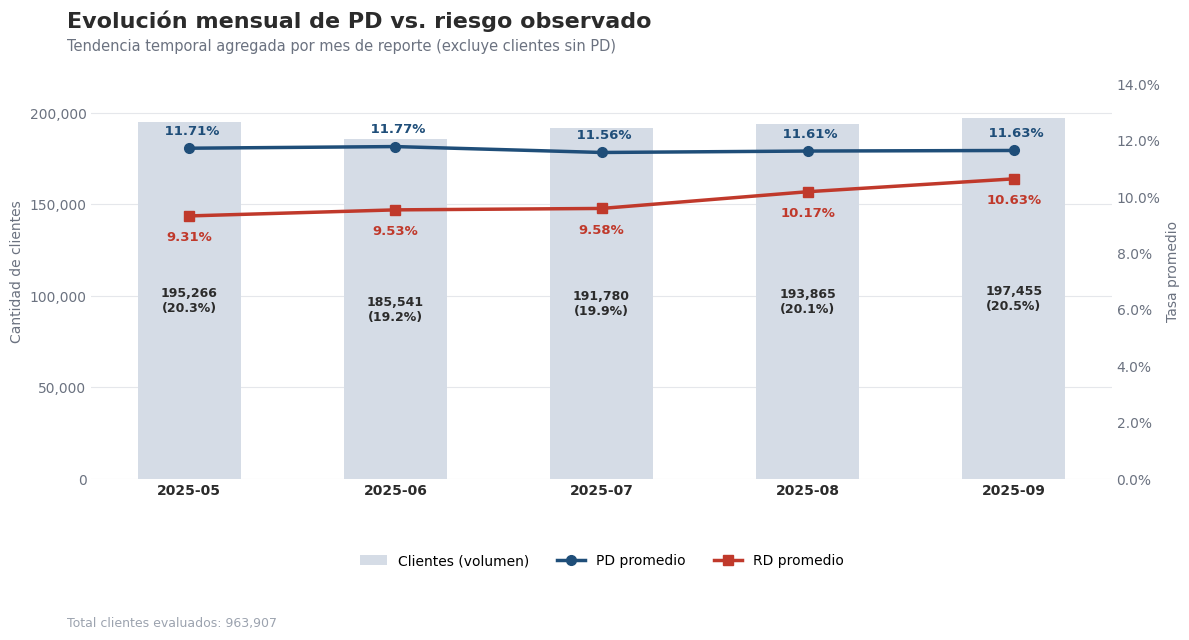

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# 1. Preparar datos temporales
df_temp = combined_df.copy()

# Convertir FEC_REPORTE a formato datetime para asegurar orden cronológico correcto
df_temp['FEC_REPORTE_DT'] = pd.to_datetime(df_temp['FEC_REPORTE'], format='%d/%m/%Y', errors='coerce')

# Agrupar por mes (YYYY-MM)
df_temp['MES'] = df_temp['FEC_REPORTE_DT'].dt.to_period('M')

# 2. Agregación de métricas por Mes
mask_val = df_temp['PD'].notnull()
col_rd = [c for c in df_temp.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd:
    target_col = col_rd[0]

    analisis_mes = (
        df_temp[mask_val].groupby('MES')
        .agg(Total_Clientes=('PD', 'size'),
             Promedio_PD_Calibrada=('PD', 'mean'),
             Promedio_RD60=(target_col, 'mean'))
        .reset_index()
    )

    analisis_mes['Pct_Clientes'] = analisis_mes['Total_Clientes'] / analisis_mes['Total_Clientes'].sum()
    analisis_mes['MES_STR'] = analisis_mes['MES'].astype(str)

    # --- Cuadro Resumen Formato Excel ---
    print("Resumen Mensual de Calibración")
    tabla_excel = analisis_mes[['MES_STR', 'Total_Clientes', 'Pct_Clientes', 'Promedio_PD_Calibrada', 'Promedio_RD60']].copy()
    tabla_excel.columns = ['Mes de Reporte', 'Total Clientes', '% Clientes', 'PD Promedio', 'RD Promedio']

    display(
        tabla_excel.style
             .format({
                 'Total Clientes': '{:,.0f}',
                 '% Clientes': '{:.1%}',
                 'PD Promedio': '{:.2%}',
                 'RD Promedio': '{:.2%}'
             })
             .hide(axis='index')
             .background_gradient(subset=['RD Promedio'], cmap='Reds')
             .set_properties(**{
                 'font-family': 'DejaVu Sans',
                 'border-collapse': 'collapse',
                 'border': '1px solid #D5DCE6',
                 'text-align': 'center'
             })
    )

    # 3. Diseño del gráfico ejecutivo por mes
    C_BAR = '#D5DCE6'
    C_PD, C_RD = '#1F4E79', '#C0392B'
    C_TXT = '#2B2B2B'

    plt.rcParams['font.family'] = 'DejaVu Sans'
    fig, ax1 = plt.subplots(figsize=(12, 6.5))
    fig.patch.set_facecolor('white')

    x = np.arange(len(analisis_mes))

    # Barras: volumen de clientes por mes
    bars = ax1.bar(x, analisis_mes['Total_Clientes'], color=C_BAR, width=0.5, zorder=2, label='Clientes (volumen)')

    for rect, tot, pct in zip(bars, analisis_mes['Total_Clientes'], analisis_mes['Pct_Clientes']):
        ax1.text(rect.get_x() + rect.get_width() / 2, rect.get_height() / 2,
                 f"{tot:,.0f}\n({pct:.1%})", ha='center', va='center',
                 fontsize=9, color=C_TXT, fontweight='bold')

    ax1.set_ylim(0, analisis_mes['Total_Clientes'].max() * 1.15)
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax1.set_ylabel('Cantidad de clientes', color='#6B7280', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(analisis_mes['MES_STR'], fontsize=10, color=C_TXT, fontweight='bold')
    ax1.tick_params(axis='y', colors='#6B7280', length=0)
    ax1.tick_params(axis='x', length=0)
    ax1.grid(axis='y', color='#E5E7EB', linewidth=0.8, zorder=0)
    ax1.set_axisbelow(True)

    # Eje secundario para PD y RD
    ax2 = ax1.twinx()

    ax2.plot(x, analisis_mes['Promedio_PD_Calibrada'], color=C_PD, marker='o',
             markersize=7, linewidth=2.5, label='PD promedio', zorder=4)
    ax2.plot(x, analisis_mes['Promedio_RD60'], color=C_RD, marker='s',
             markersize=7, linewidth=2.5, label='RD promedio', zorder=4)

    # Etiquetas de datos en las líneas
    for xi, v in zip(x, analisis_mes['Promedio_PD_Calibrada']):
        ax2.annotate(f" {v:.2%}", (xi, v), textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=9.5, color=C_PD, fontweight='bold')
    for xi, v in zip(x, analisis_mes['Promedio_RD60']):
        ax2.annotate(f"{v:.2%}", (xi, v), textcoords='offset points', xytext=(0, -18),
                     ha='center', fontsize=9.5, color=C_RD, fontweight='bold')

    ymax = max(analisis_mes['Promedio_PD_Calibrada'].max(), analisis_mes['Promedio_RD60'].max())
    ax2.set_ylim(0, ymax * 1.25)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax2.set_ylabel('Tasa promedio', color='#6B7280', fontsize=10)
    ax2.tick_params(axis='y', colors='#6B7280', length=0)

    # Eliminar bordes innecesarios
    for a in (ax1, ax2):
        for s in ('top', 'right', 'left', 'bottom'):
            a.spines[s].set_visible(False)

    # Títulos
    fig.text(0.06, 0.96, 'Evolución mensual de PD vs. riesgo observado',
             fontsize=16, fontweight='bold', color=C_TXT, ha='left', va='top')
    fig.text(0.06, 0.915,
             'Tendencia temporal agregada por mes de reporte (excluye clientes sin PD)',
             fontsize=10.5, color='#6B7280', ha='left', va='top')

    # Leyenda unificada
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.15),
               ncol=3, frameon=False, fontsize=10)

    fig.text(0.06, 0.01, f"Total clientes evaluados: {analisis_mes['Total_Clientes'].sum():,.0f}",
             fontsize=9, color='#9CA3AF', ha='left')

    plt.tight_layout(rect=[0, 0.05, 1, 0.90])
    plt.show()
else:
    print("No se encontraron columnas de riesgo observado (RD60 o FLAG_RD).")

In [44]:
from sklearn.metrics import roc_auc_score
import scipy.stats as stats

# Identificar columnas de riesgo
col_rd = [c for c in combined_df.columns if 'rd60' in c.lower() or 'flag_rd' in c.lower()]

if col_rd:
    target_col = col_rd[0]
    # 1. Filtrar registros que no sean nulos en PD y la variable de riesgo
    mask_metrics = combined_df['PD'].notnull() & combined_df[target_col].notnull()
    df_metrics = combined_df[mask_metrics]

    y_true = df_metrics[target_col].astype(int)
    y_proba = df_metrics['PD']

    # 2. Calcular Gini a partir del AUC-ROC (Gini = 2 * AUC - 1)
    auc = roc_auc_score(y_true, y_proba)
    gini = 2 * auc - 1

    # 3. Calcular la estadística KS (Kolmogorov-Smirnov)
    pd_buenos = y_proba[y_true == 0]
    pd_malos = y_proba[y_true == 1]

    ks_stat, _ = stats.ks_2samp(pd_buenos, pd_malos)

    # 4. Mostrar los resultados de forma ejecutiva
    print("=" * 40)
    print("   MÉTRICAS DE DISCRIMINACIÓN DEL MODELO")
    print("=" * 40)
    print(f"Clientes evaluados: {len(df_metrics):,}")
    print(f"Gini:               {gini:.2%}")
    print(f"KS:                 {ks_stat:.2%}")
    print("=" * 40)
else:
    print("No se encontraron columnas de riesgo observado para evaluar.")

   MÉTRICAS DE DISCRIMINACIÓN DEL MODELO
Clientes evaluados: 963,907
Gini:               40.56%
KS:                 30.10%
